<a href="https://colab.research.google.com/github/httpmarin2s/data-science-projects/blob/main/ClassificadorPaciente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Classificador de Paciente**

In [80]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree

## **Gerando Dados**

In [17]:
np.random.seed(42)  # para resultados reproduzíveis

In [58]:
n = 500
idade = np.random.randint(20,90,size=n)
pressao = np.random.randint(110,160,size=n)
batimento = np.random.randint(60,100,size=n)
colesterol = np.random.randint(150,280,size=n)

estado = []
for i in range(n): # para cada n gerado
    score = 0
    score += 1 if pressao[i] > 140 else 0
    score += 1 if colesterol[i] > 230 else 0
    score += 1 if idade[i] > 65 else 0

    # Adicionando aleatoriedade
    if score >= 2:
        estado.append(np.random.choice(["Doente", "Saudável"], p=[0.8,0.2]))
    elif score == 1:
        estado.append(np.random.choice(["Doente", "Saudável"], p=[0.5,0.5]))
    else:
        estado.append(np.random.choice(["Doente", "Saudável"], p=[0.2,0.8]))

In [59]:
# Criando dados de exemplo
dados = {
    "idade": idade,
    "pressao_arterial": pressao,
    "batimento_cardiaco": batimento,
    "colesterol": colesterol,
    "estado":estado
}

dados = pd.DataFrame(dados)

In [60]:
dados.head()

,idade,pressao_arterial,batimento_cardiaco,colesterol,estado
0,31,155,93,183,Doente
1,68,128,81,278,Doente
2,61,141,82,238,Doente
3,57,118,62,242,Doente
4,64,121,93,220,Doente


# **Análise Inicial**

In [61]:
def analise_inicial(df):
  print(df.shape) # verificar linhas e colunas
  print(df.info()) # verificar informações gerais
  print(df.describe()) # verificar dados estatísticos

In [62]:
analise_inicial(dados)

(500, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   idade               500 non-null    int64 
 1   pressao_arterial    500 non-null    int64 
 2   batimento_cardiaco  500 non-null    int64 
 3   colesterol          500 non-null    int64 
 4   estado              500 non-null    object
dtypes: int64(4), object(1)
memory usage: 19.7+ KB
None
            idade  pressao_arterial  batimento_cardiaco  colesterol
count  500.000000        500.000000          500.000000  500.000000
mean    53.104000        135.168000           80.072000  217.700000
std     20.487476         14.474765           11.276397   36.242641
min     20.000000        110.000000           60.000000  150.000000
25%     35.000000        123.000000           70.000000  188.000000
50%     51.000000        136.000000           80.000000  217.000000
75%     71.000000  

## **Codificando a variável alvo**

In [63]:
dados['estado'] = dados['estado'].replace({'Saudável': 0, 'Doente': 1})
# indico para o modelo que minha variável 1 é doente

/tmp/ipython-input-2700223805.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dados['estado'] = dados['estado'].replace({'Saudável': 0, 'Doente': 1})


In [64]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   idade               500 non-null    int64
 1   pressao_arterial    500 non-null    int64
 2   batimento_cardiaco  500 non-null    int64
 3   colesterol          500 non-null    int64
 4   estado              500 non-null    int64
dtypes: int64(5)
memory usage: 19.7 KB


## **Separação de Dados**

In [65]:
# X = features, y = label
X = dados[["idade", "pressao_arterial", "batimento_cardiaco", "colesterol"]]
y = dados["estado"]

In [66]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
                                        X,
                                        y,
                                        test_size=0.4,
                                        random_state=42
)

## **Criando o Modelo de Machine Learning - Árvores de Decisão**

In [67]:
modelo = RandomForestClassifier(
    n_estimators=100,        # número de árvores
    max_depth=5,             # profundidade máxima de cada árvore
    min_samples_split=10,    # mínimo para dividir um nó
    min_samples_leaf=5,      # mínimo de amostras por folha
    random_state=42
)

In [68]:
modelo.fit(X_treino, y_treino)

RandomForestClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

## **Testando o modelo com previsões**

In [69]:
previsoes = modelo.predict(X_teste)
print(previsoes)

[1 0 1 1 0 0 1 0 1 1 1 1 0 0 0 1 1 1 1 1 0 0 1 0 1 1 1 0 0 0 0 1 0 1 1 1 1
 1 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 0 1 1 0 0 0 0 1 1 0 0 1 0 0
 1 1 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 0 1 0
 1 1 1 1 1 0 1 0 1 0 1 1 0 1 0 0 0 1 1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 0 0 0
 1 1 0 0 0 1 1 0 1 0 1 0 1 1 1 1 1 0 0 0 0 1 1 0 0 1 0 1 0 1 1 0 0 0 1 0 1
 0 0 0 1 0 0 0 1 1 0 0 1 0 0 1]


## **Avaliando o Modelo**

In [70]:
print(classification_report(y_teste, previsoes))
print(confusion_matrix(y_teste, previsoes))

              precision    recall  f1-score   support

           0       0.73      0.61      0.67        98
           1       0.68      0.78      0.73       102

    accuracy                           0.70       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.70      0.70      0.70       200

[[60 38]
 [22 80]]


## **Visualizando**

In [73]:
importancia = modelo.feature_importances_
features = X.columns

In [76]:
df_importancia = pd.DataFrame({
    "Features": features,
    "Importancia": importancia
}).sort_values(by='Importancia', ascending=False)

/tmp/ipython-input-2194756774.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Features', data=df_importancia, palette="viridis")


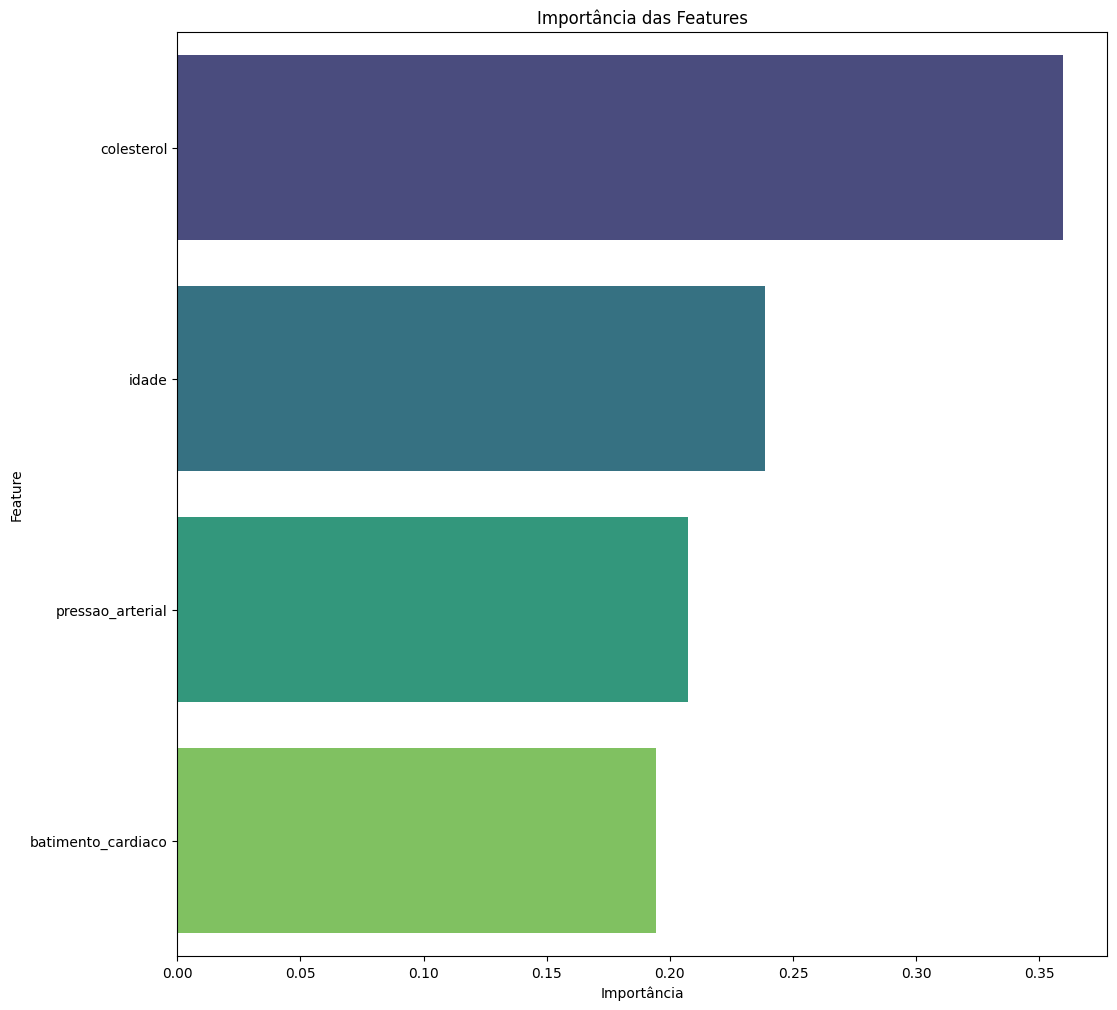

In [79]:
plt.figure(figsize=(12,12))
sns.barplot(x='Importancia', y='Features', data=df_importancia, palette="viridis")
plt.title("Importância das Features")
plt.xlabel("Importância")
plt.ylabel("Feature")
plt.show()

In [81]:
arvore = modelo.estimators_[0]
# selecionamos a primeira árvore lemrbrando que criamos 100 estimadores

In [83]:
classes = []

for c in modelo.classes_:
    classes.append(str(c))

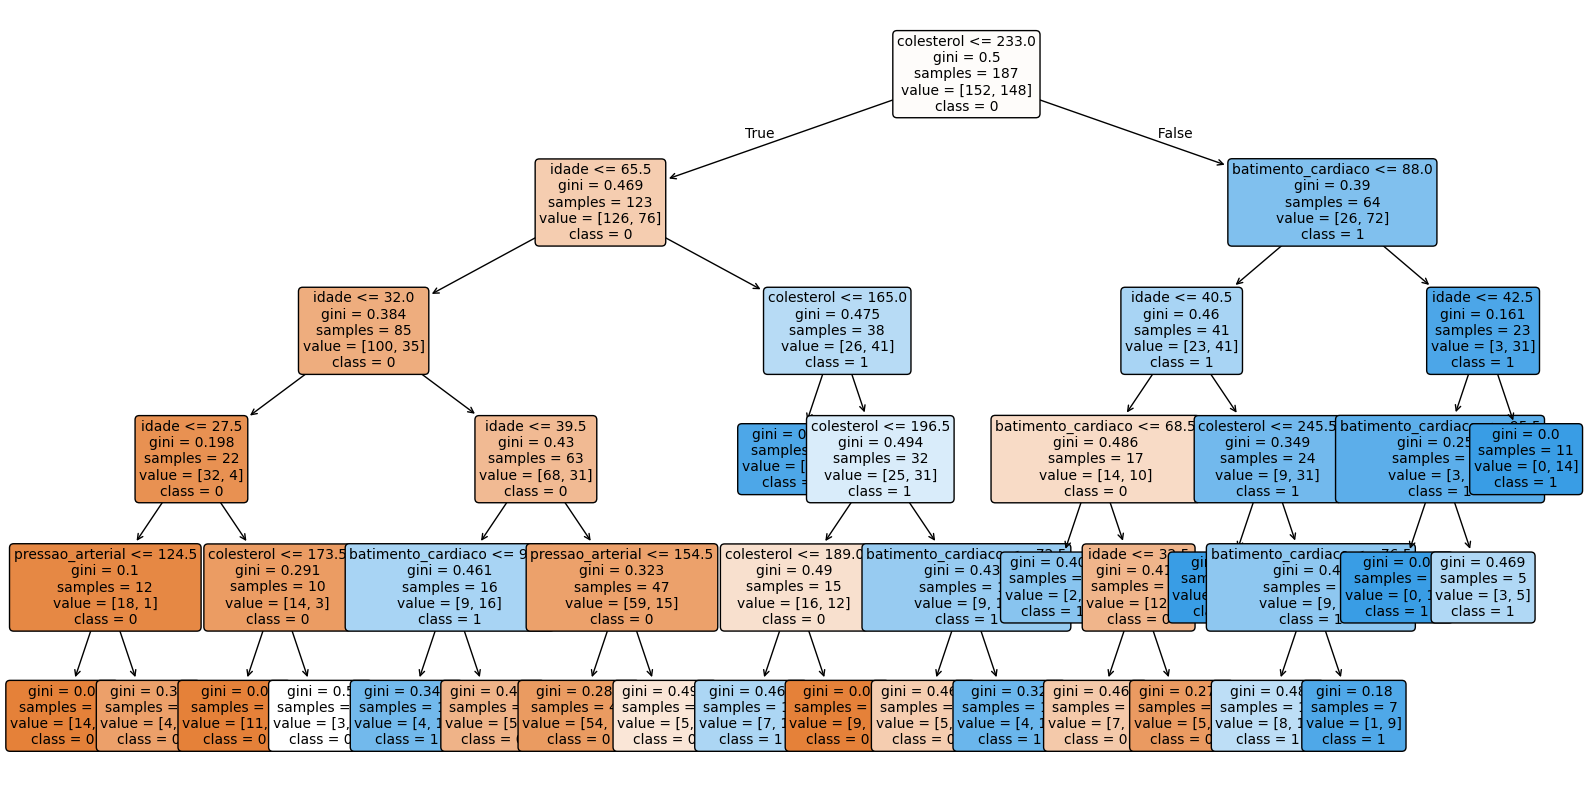

In [84]:
plt.figure(figsize=(20,10))
plot_tree(
    arvore,
    feature_names=X.columns,
    class_names=classes,
    filled=True,        # colore os nós pelo valor da classe
    rounded=True,
    fontsize=10
)
plt.show()

## **Script Interativo**

In [130]:
pacientes = []

In [133]:
num_pacientes = int(input("Quantos pacientes você quer cadastrar? "))

Quantos pacientes você quer cadastrar? 5


In [134]:
for i in range(num_pacientes):
  print(f'\n Cadastro do Paciente {i+1}: ')

  idade = int(input("Digite a idade do paciente: "))
  pressao = int(input("Digite a pressão arterial do paciente: "))
  batimento = int(input("Digite o batimento cardíaco do paciente: "))
  colesterol = int(input("Digite o colesterol do paciente: "))

  # adicionando a lista
  pacientes.append({
      "idade": idade,
      "pressao_arterial": pressao,
      "batimento_cardiaco": batimento,
      "colesterol": colesterol
  })


 Cadastro do Paciente 1: 
Digite a idade do paciente: 25
Digite a pressão arterial do paciente: 115
Digite o batimento cardíaco do paciente: 68
Digite o colesterol do paciente: 180

 Cadastro do Paciente 2: 
Digite a idade do paciente: 70
Digite a pressão arterial do paciente: 145
Digite o batimento cardíaco do paciente: 90
Digite o colesterol do paciente: 250

 Cadastro do Paciente 3: 
Digite a idade do paciente: 50
Digite a pressão arterial do paciente: 135
Digite o batimento cardíaco do paciente: 75
Digite o colesterol do paciente: 220

 Cadastro do Paciente 4: 
Digite a idade do paciente: 35
Digite a pressão arterial do paciente: 125
Digite o batimento cardíaco do paciente: 72
Digite o colesterol do paciente: 200

 Cadastro do Paciente 5: 
Digite a idade do paciente: 65
Digite a pressão arterial do paciente: 150
Digite o batimento cardíaco do paciente: 85
Digite o colesterol do paciente: 250


In [135]:
novos_pacientes = pd.DataFrame(pacientes)

In [136]:
previsoes = modelo.predict(novos_pacientes)

In [137]:
# Função para calcular risco de 0 a 100%
probs = modelo.predict_proba(novos_pacientes)[:, 1]  # pega só a coluna da classe 1 (Doente)


In [138]:
mapa_estado = {0: "Saudável", 1: "Doente"}
total_saudaveis = 0
total_doentes = 0

In [139]:
print("\nResultados do simulador de risco (com probabilidade):")
for i, linha in novos_pacientes.iterrows():
    previsao_str = mapa_estado[previsoes[i]]
    risco = round(probs[i] * 100, 1)  # transformar em percentual

    if previsao_str == "Saudável":
        emoji = "✅"
        mensagem = "Tudo certo!"
        total_saudaveis += 1
    else:
        emoji = "⚠️"
        mensagem = "Cuidado!"
        total_doentes += 1

    print(f"Paciente {i+1}: {previsao_str} {emoji} - {mensagem} | Risco de estar doente: {risco}%")



Resultados do simulador de risco (com probabilidade):
Paciente 1: Saudável ✅ - Tudo certo! | Risco de estar doente: 24.5%
Paciente 2: Doente ⚠️ - Cuidado! | Risco de estar doente: 89.2%
Paciente 3: Saudável ✅ - Tudo certo! | Risco de estar doente: 27.9%
Paciente 4: Saudável ✅ - Tudo certo! | Risco de estar doente: 29.9%
Paciente 5: Doente ⚠️ - Cuidado! | Risco de estar doente: 83.7%


In [140]:
# Resumo final
print("\nResumo final:")
print(f"Total de pacientes saudáveis: {total_saudaveis} ✅")
print(f"Total de pacientes doentes: {total_doentes} ⚠️")


Resumo final:
Total de pacientes saudáveis: 3 ✅
Total de pacientes doentes: 2 ⚠️
